In [ ]:
import cv2 as cv
import numpy as np

img1=cv.imread('./ch5/mot_color70.jpg')[190:350,440:560] # 버스를 크롭하여 모델 영상으로 사용
gray1=cv.cvtColor(img1,cv.COLOR_BGR2GRAY)
img2=cv.imread('./ch5/mot_color83.jpg')			     # 장면 영상
gray2=cv.cvtColor(img2,cv.COLOR_BGR2GRAY)

sift=cv.SIFT_create()
kp1,des1=sift.detectAndCompute(gray1,None)
kp2,des2=sift.detectAndCompute(gray2,None)

flann_matcher=cv.DescriptorMatcher_create(cv.DescriptorMatcher_FLANNBASED)
knn_match=flann_matcher.knnMatch(des1,des2,2)	# 최근접 2개

T=0.7
good_match=[]
for nearest1,nearest2 in knn_match:
    if (nearest1.distance/nearest2.distance)<T:
        good_match.append(nearest1)

points1=np.float32([kp1[gm.queryIdx].pt for gm in good_match])
points2=np.float32([kp2[gm.trainIdx].pt for gm in good_match])

H,_=cv.findHomography(points1,points2,cv.RANSAC)

h1,w1=img1.shape[0],img1.shape[1] 		# 첫 번째 영상의 크기
h2,w2=img2.shape[0],img2.shape[1] 		# 두 번째 영상의 크기

box1=np.float32([[0,0],[0,h1-1],[w1-1,h1-1],[w1-1,0]]).reshape(4,1,2)
box2=cv.perspectiveTransform(box1,H)

img2=cv.polylines(img2,[np.int32(box2)],True,(0,255,0),8)

img_match=np.empty((max(h1,h2),w1+w2,3),dtype=np.uint8)
cv.drawMatches(img1,kp1,img2,kp2,good_match,img_match,flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
   
cv.imshow('Matches and Homography',img_match)

k=cv.waitKey()
cv.destroyAllWindows()

In [ ]:
import cv2 as cv
import numpy as np

img1=cv.imread('./lacko-3.png') # 버스를 크롭하여 모델 영상으로 사용
gray1=cv.cvtColor(img1,cv.COLOR_BGR2GRAY)
img2=cv.imread('./lacko-1.png')			     # 장면 영상
gray2=cv.cvtColor(img2,cv.COLOR_BGR2GRAY)

sift=cv.SIFT_create()
kp1,des1=sift.detectAndCompute(gray1,None)
kp2,des2=sift.detectAndCompute(gray2,None)

flann_matcher=cv.DescriptorMatcher_create(cv.DescriptorMatcher_FLANNBASED)
knn_match=flann_matcher.knnMatch(des1,des2,2)	# 최근접 2개

T=0.7
good_match=[]
for nearest1,nearest2 in knn_match:
    if (nearest1.distance/nearest2.distance)<T:
        good_match.append(nearest1)

points1=np.float32([kp1[gm.queryIdx].pt for gm in good_match])
points2=np.float32([kp2[gm.trainIdx].pt for gm in good_match])

H,_=cv.findHomography(points1,points2,cv.RANSAC)

h1,w1=img1.shape[0],img1.shape[1] 		# 첫 번째 영상의 크기
h2,w2=img2.shape[0],img2.shape[1] 		# 두 번째 영상의 크기

box1=np.float32([[0,0],[0,h1-1],[w1-1,h1-1],[w1-1,0]]).reshape(4,1,2)
box2=cv.perspectiveTransform(box1,H)

img2=cv.polylines(img2,[np.int32(box2)],True,(0,255,0),8)

img_match=np.empty((max(h1,h2),w1+w2,3),dtype=np.uint8)
cv.drawMatches(img1,kp1,img2,kp2,good_match,img_match,flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
   
cv.imshow('Matches and Homography',img_match)

k=cv.waitKey()
cv.destroyAllWindows()

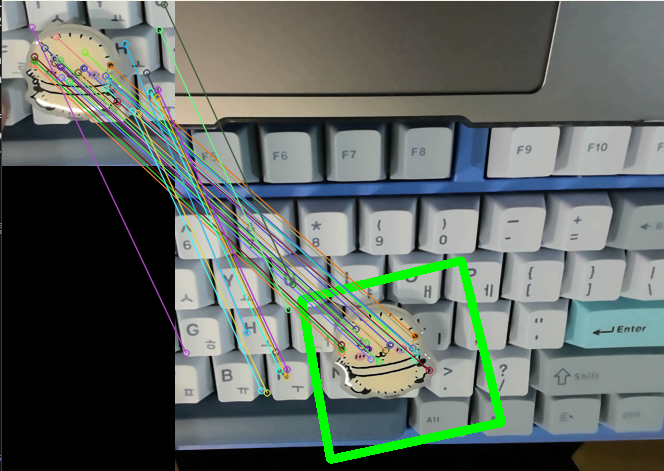

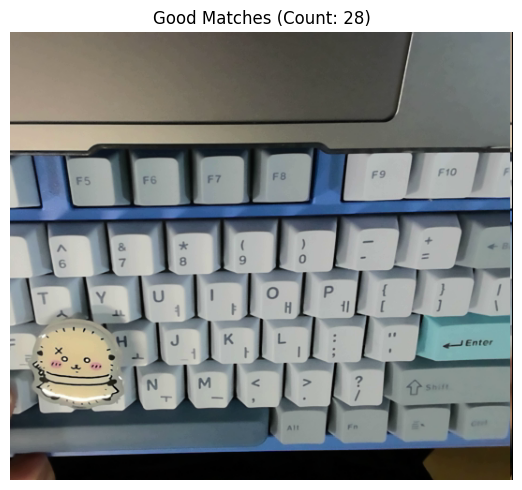

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

img1=cv.imread('./lacko-2.png')[300:400, 0:150] # 버스를 크롭하여 모델 영상으로 사용
gray1=cv.cvtColor(img1,cv.COLOR_BGR2GRAY)
img2=cv.imread('./lacko-1.png')			     # 장면 영상
gray2=cv.cvtColor(img2,cv.COLOR_BGR2GRAY)

#sift 객체를 생성하고 특징점 검출
sift=cv.SIFT_create()
kp1,des1=sift.detectAndCompute(gray1,None)
kp2,des2=sift.detectAndCompute(gray2,None)

#flann 기반으로 knn 매칭 수행
flann_matcher=cv.DescriptorMatcher_create(cv.DescriptorMatcher_FLANNBASED)
knn_match=flann_matcher.knnMatch(des1,des2,2)	# 최근접 2개

T=0.7
good_match=[]
#1등 매칭점이 2등 매칭점보다 월등하게 비슷할때만 진짜 유효한 매칭점으로 인정하고 저장한다.
for nearest1,nearest2 in knn_match:
    if (nearest1.distance/nearest2.distance)<T:
        good_match.append(nearest1)

#첫번째 이미지의 특징점을 저장
points1=np.float32([kp1[gm.queryIdx].pt for gm in good_match])
#두번째 이미지의 특징점 저장
points2=np.float32([kp2[gm.trainIdx].pt for gm in good_match])

#란삭 알고리즘 수행
H,_=cv.findHomography(points1,points2,cv.RANSAC)

#첫번째 작은 라코 사진
h1,w1=img1.shape[0],img1.shape[1] 		# 첫 번째 영상의 크기
#두번째 전체 사진
h2,w2=img2.shape[0],img2.shape[1] 		# 두 번째 영상의 크기

#랏코 이미지의 모서리 좌표
box1=np.float32([[0,0],[0,h1-1],[w1-1,h1-1],[w1-1,0]]).reshape(4,1,2)
#앞에서 구한 호모그래피 행렬을 box1에 적용해서 2번째 그림에서 랏코 위치 추측해서 꼭짓점 좌표 전달
box2=cv.perspectiveTransform(box1,H)

#앞에서 box2에 저장된 네 모서리를 기준으로 박스 그리기
img2=cv.polylines(img2,[np.int32(box2)],True,(0,255,0),8)

#두개 사진에서 특징점들을 이어 제대로 매칭이 되었는지 확인
img_match=np.empty((max(h1,h2),w1+w2,3),dtype=np.uint8)
cv.drawMatches(img1,kp1,img2,kp2,good_match,img_match,flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
   
cv.imshow('Matches and Homography',img_match)

k=cv.waitKey()
cv.destroyAllWindows()

img1 =cv.imread('./lacko-2.png')
img2_rgb = cv.cvtColor(img1, cv.COLOR_BGR2RGB)
plt.figure(figsize=(7, 5))
plt.imshow(img2_rgb)
plt.title(f'Good Matches (Count: {len(good_match)})')
plt.axis('off') # 눈금선 제거
plt.tight_layout()
plt.show()

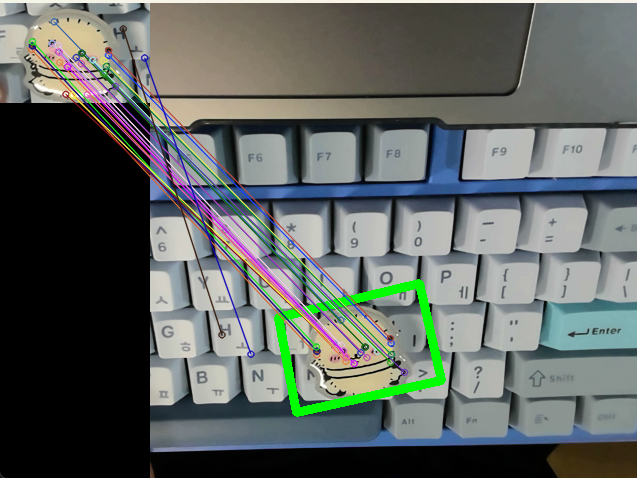

In [1]:
from PyQt5.QtWidgets import *
import sys
import winsound

class BeepSound(QMainWindow):
    def __init__(self) :
        super().__init__()
        self.setWindowTitle('삑 소리 내기') 		# 윈도우 이름과 위치 지정
        self.setGeometry(200,200,500,100)

        shortBeepButton=QPushButton('짧게 삑',self)	# 버튼 생성
        longBeepButton=QPushButton('길게 삑',self)
        quitButton=QPushButton('나가기',self)
        self.label=QLabel('환영합니다!',self)
        
        shortBeepButton.setGeometry(10,10,100,30)	# 버튼 위치와 크기 지정
        longBeepButton.setGeometry(110,10,100,30)
        quitButton.setGeometry(210,10,100,30)
        self.label.setGeometry(10,40,500,70)
        
        shortBeepButton.clicked.connect(self.shortBeepFunction) # 콜백 함수 지정
        longBeepButton.clicked.connect(self.longBeepFunction)         
        quitButton.clicked.connect(self.quitFunction)
       
    def shortBeepFunction(self):
        self.label.setText('주파수 1000으로 0.5초 동안 삑 소리를 냅니다.')   
        winsound.Beep(1000,500)
        
    def longBeepFunction(self):
        self.label.setText('주파수 1000으로 3초 동안 삑 소리를 냅니다.')        
        winsound.Beep(1000,3000) 
                
    def quitFunction(self):
        self.close()
                
app=QApplication(sys.argv) 
win=BeepSound() 
win.show()
app.exec_()

0

In [1]:
from PyQt5.QtWidgets import *
import sys
import cv2 as cv
       
class Video(QMainWindow):
    def __init__(self) :
        super().__init__()
        self.setWindowTitle('비디오에서 프레임 수집')	# 윈도우 이름과 위치 지정
        self.setGeometry(200,200,500,100)

        videoButton=QPushButton('비디오 켜기',self)	# 버튼 생성
        captureButton=QPushButton('프레임 잡기',self)
        saveButton=QPushButton('프레임 저장',self)
        quitButton=QPushButton('나가기',self)

        #x,y 위치 너비, 높이
        videoButton.setGeometry(10,10,100,30)		# 버튼 위치와 크기 지정
        captureButton.setGeometry(110,10,100,30)
        saveButton.setGeometry(210,10,100,30)
        quitButton.setGeometry(310,10,100,30)

        #해당 버튼을 클릭하면 함수와 연결되게함
        videoButton.clicked.connect(self.videoFunction) # 콜백 함수 지정
        captureButton.clicked.connect(self.captureFunction)         
        saveButton.clicked.connect(self.saveFunction)
        quitButton.clicked.connect(self.quitFunction)
       
    def videoFunction(self):
        self.cap=cv.VideoCapture(0,cv.CAP_DSHOW)	# 카메라와 연결 시도
        if not self.cap.isOpened(): self.close()
            
        while True:
            #각각 변수 읽어오기
            ret,self.frame=self.cap.read() 
            #ret가 없으면 break
            if not ret: break            
            cv.imshow('video display',self.frame)
            cv.waitKey(1)
        
    def captureFunction(self):
        #self.frame 캡쳐하기
        self.capturedFrame=self.frame
        cv.imshow('Captured Frame',self.capturedFrame)
        
    def saveFunction(self):
        fname = QFileDialog.getSaveFileName(self, '파일 저장', './')
        if fname[0] == '':
            return

        # 파일 확장자 확인
        ext = fname[0].split('.')[-1]

        # 이미지를 메모리에서 인코딩
        result, encoded_img = cv.imencode('.' + ext, self.capturedFrame)

        if result:
            # 한글 경로에도 저장 가능
            encoded_img.tofile(fname[0])
            print("저장 경로:", fname[0])
            print("저장 성공")
        else:
            print("저장 실패")
        
    def quitFunction(self):
        self.cap.release()				# 카메라와 연결을 끊음
        cv.destroyAllWindows()
        self.close()
                
app=QApplication(sys.argv)
win=Video() 
win.show()
app.exec_()

저장 경로: C:/Users/smart/OneDrive/바탕 화면/코드/me.png
저장 성공


0

In [1]:
import cv2 as cv 
import numpy as np
import sys
from PyQt5.QtWidgets import *
      
class Orim(QMainWindow):
    def __init__(self) :
        super().__init__()
        self.setWindowTitle('오림')
        self.setGeometry(200,200,700,200)
       
        fileButton=QPushButton('파일',self)
        paintButton=QPushButton('페인팅',self)
        cutButton=QPushButton('오림',self)
        incButton=QPushButton('+',self)
        decButton=QPushButton('-',self)
        saveButton=QPushButton('저장',self)
        quitButton=QPushButton('나가기',self)
        
        fileButton.setGeometry(10,10,100,30)
        paintButton.setGeometry(110,10,100,30)
        cutButton.setGeometry(210,10,100,30)
        incButton.setGeometry(310,10,50,30)
        decButton.setGeometry(360,10,50,30)
        saveButton.setGeometry(410,10,100,30)
        quitButton.setGeometry(510,10,100,30)
        
        fileButton.clicked.connect(self.fileOpenFunction)
        paintButton.clicked.connect(self.paintFunction) 
        cutButton.clicked.connect(self.cutFunction)    
        incButton.clicked.connect(self.incFunction)              
        decButton.clicked.connect(self.decFunction) 
        saveButton.clicked.connect(self.saveFunction)                         
        quitButton.clicked.connect(self.quitFunction)

        self.BrushSiz=5			# 페인팅 붓의 크기
        self.LColor,self.RColor=(255,0,0),(0,0,255) # 파란색 물체, 빨간색 배경
        
    def fileOpenFunction(self):
        fname=QFileDialog.getOpenFileName(self,'Open file','./')
        self.img=cv.imread(fname[0])
        if self.img is None: sys.exit('파일을 찾을 수 없습니다.')  
        
        self.img_show=np.copy(self.img)	# 표시용 영상 
        cv.imshow('Painting',self.img_show)
        
        self.mask=np.zeros((self.img.shape[0],self.img.shape[1]),np.uint8) 
        self.mask[:,:]=cv.GC_PR_BGD	# 모든 화소를 배경일 것 같음으로 초기화
            
    def paintFunction(self):
        cv.setMouseCallback('Painting',self.painting) 
        
    def painting(self,event,x,y,flags,param):
        if event==cv.EVENT_LBUTTONDOWN:   
            cv.circle(self.img_show,(x,y),self.BrushSiz,self.LColor,-1) # 왼쪽 버튼을 클릭하면 파란색
            cv.circle(self.mask,(x,y),self.BrushSiz,cv.GC_FGD,-1)
        elif event==cv.EVENT_RBUTTONDOWN: 
            cv.circle(self.img_show,(x,y),self.BrushSiz,self.RColor,-1) # 오른쪽 버튼을 클릭하면 빨간색
            cv.circle(self.mask,(x,y),self.BrushSiz,cv.GC_BGD,-1)
        elif event==cv.EVENT_MOUSEMOVE and flags==cv.EVENT_FLAG_LBUTTON:
            cv.circle(self.img_show,(x,y),self.BrushSiz,self.LColor,-1) # 왼쪽 버튼을 클릭하고 이동하면 파란색
            cv.circle(self.mask,(x,y),self.BrushSiz,cv.GC_FGD,-1)
        elif event==cv.EVENT_MOUSEMOVE and flags==cv.EVENT_FLAG_RBUTTON:
            cv.circle(self.img_show,(x,y),self.BrushSiz,self.RColor,-1) # 오른쪽 버튼을 클릭하고 이동하면 빨간색 
            cv.circle(self.mask,(x,y),self.BrushSiz,cv.GC_BGD,-1)
    
        cv.imshow('Painting',self.img_show)        
        
    def cutFunction(self):
        background=np.zeros((1,65),np.float64) 
        foreground=np.zeros((1,65),np.float64) 
        cv.grabCut(self.img,self.mask,None,background,foreground,5,cv.GC_INIT_WITH_MASK)
        mask2=np.where((self.mask==2)|(self.mask==0),0,1).astype('uint8')
        self.grabImg=self.img*mask2[:,:,np.newaxis]
        cv.imshow('Scissoring',self.grabImg) 
        
    def incFunction(self):
        self.BrushSiz=min(20,self.BrushSiz+1) 
        
    def decFunction(self):
        self.BrushSiz=max(1,self.BrushSiz-1) 
        
    def saveFunction(self):
        fname=QFileDialog.getSaveFileName(self,'파일 저장','./')
        cv.imwrite(fname[0],self.grabImg)
                
    def quitFunction(self):
        cv.destroyAllWindows()        
        self.close()
                
app=QApplication(sys.argv) 
win=Orim() 
win.show()
app.exec_()

: 

In [1]:
import cv2 as cv 
import numpy as np
import sys
from PyQt5.QtWidgets import *

class Orim(QMainWindow):
    def __init__(self):
        super().__init__()
        self.setWindowTitle('오림')
        self.setGeometry(200, 200, 700, 200)

        # 멤버 변수 안전하게 초기화
        self.img = None
        self.img_show = None
        self.mask = None
        self.grabImg = None

        fileButton = QPushButton('파일', self)
        paintButton = QPushButton('페인팅', self)
        cutButton = QPushButton('오림', self)
        incButton = QPushButton('+', self)
        decButton = QPushButton('-', self)
        saveButton = QPushButton('저장', self)
        quitButton = QPushButton('나가기', self)
        
        fileButton.setGeometry(10, 10, 100, 30)
        paintButton.setGeometry(110, 10, 100, 30)
        cutButton.setGeometry(210, 10, 100, 30)
        incButton.setGeometry(310, 10, 50, 30)
        decButton.setGeometry(360, 10, 50, 30)
        saveButton.setGeometry(410, 10, 100, 30)
        quitButton.setGeometry(510, 10, 100, 30)
        
        fileButton.clicked.connect(self.fileOpenFunction)
        paintButton.clicked.connect(self.paintFunction) 
        cutButton.clicked.connect(self.cutFunction)    
        incButton.clicked.connect(self.incFunction)              
        decButton.clicked.connect(self.decFunction) 
        saveButton.clicked.connect(self.saveFunction)                         
        quitButton.clicked.connect(self.quitFunction)

        self.BrushSiz = 5                           # 페인팅 붓의 크기
        self.LColor, self.RColor = (255, 0, 0), (0, 0, 255) # 파란색 물체, 빨간색 배경
        
    def fileOpenFunction(self):
        fname = QFileDialog.getOpenFileName(self, 'Open file', './', 'Images (*.png *.jpg *.jpeg *.bmp)')
        
        # 파일이 선택되었는지 확인 (취소 누른 경우 예외 처리)
        if fname[0]:
            img_array = np.fromfile(fname[0], np.uint8)
            self.img = cv.imdecode(img_array, cv.IMREAD_COLOR)
            if self.img is None:
                QMessageBox.critical(self, "오류", "이미지 파일을 불러올 수 없습니다.")
                return
            
            self.img_show = np.copy(self.img) # 표시용 영상 
            cv.imshow('Painting', self.img_show)
            
            self.mask = np.zeros((self.img.shape[0], self.img.shape[1]), np.uint8) 
            self.mask[:, :] = cv.GC_PR_BGD # 모든 화소를 배경일 것 같음으로 초기화
            self.grabImg = None # 새로운 파일 등록 시 기존 오림 이미지 초기화
            
    def paintFunction(self):
        if self.img_show is None:
            QMessageBox.warning(self, "경고", "먼저 이미지 파일을 열어주세요.")
            return
        cv.setMouseCallback('Painting', self.painting) 
        
    def painting(self, event, x, y, flags, param):
        if self.img_show is None:
            return

        if event == cv.EVENT_LBUTTONDOWN or (event == cv.EVENT_MOUSEMOVE and flags == cv.EVENT_FLAG_LBUTTON):
            cv.circle(self.img_show, (x, y), self.BrushSiz, self.LColor, -1) # 왼쪽 버튼/드래그: 파란색
            cv.circle(self.mask, (x, y), self.BrushSiz, cv.GC_FGD, -1)
        elif event == cv.EVENT_RBUTTONDOWN or (event == cv.EVENT_MOUSEMOVE and flags == cv.EVENT_FLAG_RBUTTON):
            cv.circle(self.img_show, (x, y), self.BrushSiz, self.RColor, -1) # 오른쪽 버튼/드래그: 빨간색
            cv.circle(self.mask, (x, y), self.BrushSiz, cv.GC_BGD, -1)
    
        cv.imshow('Painting', self.img_show)        
        
    def cutFunction(self):
        if self.img is None or self.mask is None:
            QMessageBox.warning(self, "경고", "먼저 이미지를 불러오고 페인팅 작업을 해주세요.")
            return

        background = np.zeros((1, 65), np.float64) 
        foreground = np.zeros((1, 65), np.float64) 
        cv.grabCut(self.img, self.mask, None, background, foreground, 5, cv.GC_INIT_WITH_MASK)
        mask2 = np.where((self.mask == 2) | (self.mask == 0), 0, 1).astype('uint8')
        self.grabImg = self.img * mask2[:, :, np.newaxis]
        cv.imshow('Scissoring', self.grabImg) 
        
    def incFunction(self):
        self.BrushSiz = min(20, self.BrushSiz + 1) 
        
    def decFunction(self):
        self.BrushSiz = max(1, self.BrushSiz - 1) 
    def saveFunction(self):
        if self.grabImg is None:
            QMessageBox.warning(self, "경고", "저장할 오림 이미지가 없습니다. [오림] 버튼을 먼저 실행하세요.")
            return

        fname = QFileDialog.getSaveFileName(self, '파일 저장', './', 'PNG Files (*.png);;JPG Files (*.jpg)')
        
        if fname[0]:
            filePath = fname[0]
            
            # 1. 확장자가 없는 경우 기본값(.png) 추가
            if not filePath.lower().endswith(('.png', '.jpg', '.jpeg')):
                filePath += '.png'

            # 2. 파일 확장자 추출 (.png 또는 .jpg)
            ext = '.' + filePath.split('.')[-1].lower()

            # 3. 한글 경로를 지원하는 메모리 인코딩 후 저장 방식
            result, encoded_img = cv.imencode(ext, self.grabImg)

            if result:
                encoded_img.tofile(filePath) # 한글 경로 파일 저장 완료
                QMessageBox.information(self, "성공", f"성공적으로 저장되었습니다:\n{filePath}")
            else:
                QMessageBox.critical(self, "오류", "이미지 인코딩에 실패했습니다.")
                
    def quitFunction(self):
        cv.destroyAllWindows()        
        self.close()

if __name__ == '__main__':
    app = QApplication(sys.argv) 
    win = Orim() 
    win.show()
    sys.exit(app.exec_())

SystemExit: 0

C:\Users\smart\AppData\Roaming\Python\Python312\site-packages\IPython\core\interactiveshell.py:3756: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


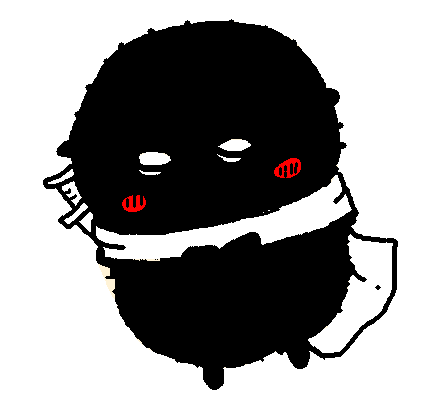

In [1]:
import cv2 as cv 
import numpy as np
import sys
from PyQt5.QtWidgets import *

class Orim(QMainWindow):
    def __init__(self):
        super().__init__()
        self.setWindowTitle('오림')
        self.setGeometry(200, 200, 700, 200)

        # 멤버 변수 안전하게 초기화
        self.img = None
        self.img_show = None
        self.mask = None
        self.grabImg = None

        fileButton = QPushButton('파일', self)
        paintButton = QPushButton('페인팅', self)
        cutButton = QPushButton('오림', self)
        incButton = QPushButton('+', self)
        decButton = QPushButton('-', self)
        saveButton = QPushButton('저장', self)
        quitButton = QPushButton('나가기', self)
        
        fileButton.setGeometry(10, 10, 100, 30)
        paintButton.setGeometry(110, 10, 100, 30)
        cutButton.setGeometry(210, 10, 100, 30)
        incButton.setGeometry(310, 10, 50, 30)
        decButton.setGeometry(360, 10, 50, 30)
        saveButton.setGeometry(410, 10, 100, 30)
        quitButton.setGeometry(510, 10, 100, 30)
        
        fileButton.clicked.connect(self.fileOpenFunction)
        paintButton.clicked.connect(self.paintFunction) 
        cutButton.clicked.connect(self.cutFunction)    
        incButton.clicked.connect(self.incFunction)              
        decButton.clicked.connect(self.decFunction) 
        saveButton.clicked.connect(self.saveFunction)                         
        quitButton.clicked.connect(self.quitFunction)

        self.BrushSiz = 5                           # 페인팅 붓의 크기
        self.LColor, self.RColor = (255, 0, 0), (0, 0, 255) # 파란색 물체, 빨간색 배경
        
    def fileOpenFunction(self):
        fname = QFileDialog.getOpenFileName(self, 'Open file', './', 'Images (*.png *.jpg *.jpeg *.bmp)')
        
        # 파일이 선택되었는지 확인 (취소 누른 경우 예외 처리)
        if fname[0]:
            img_array = np.fromfile(fname[0], np.uint8)
            self.img = cv.imdecode(img_array, cv.IMREAD_COLOR)
            if self.img is None:
                QMessageBox.critical(self, "오류", "이미지 파일을 불러올 수 없습니다.")
                return
            
            self.img_show = np.copy(self.img) # 표시용 영상 
            cv.imshow('Painting', self.img_show)
            
            self.mask = np.zeros((self.img.shape[0], self.img.shape[1]), np.uint8) 
            self.mask[:, :] = cv.GC_PR_BGD # 모든 화소를 배경일 것 같음으로 초기화
            self.grabImg = None # 새로운 파일 등록 시 기존 오림 이미지 초기화
            
    def paintFunction(self):
        if self.img_show is None:
            QMessageBox.warning(self, "경고", "먼저 이미지 파일을 열어주세요.")
            return
        cv.setMouseCallback('Painting', self.painting) 
        
    def painting(self,event,x,y,flags,param):
        if event==cv.EVENT_LBUTTONDOWN:
            pts=np.array([[x,y-20],[x-20,y+20],[x+20,y+20]],np.int32)
            cv.fillPoly(self.img_show,[pts],self.LColor)
            cv.fillPoly(self.mask,[pts],cv.GC_FGD)

        elif event==cv.EVENT_RBUTTONDOWN:
            cv.rectangle(self.img_show,(x-20,y-20),(x+20,y+20),self.RColor,-1)
            cv.rectangle(self.mask,(x-20,y-20),(x+20,y+20),cv.GC_BGD,-1)

        elif event==cv.EVENT_MOUSEMOVE and flags==cv.EVENT_FLAG_LBUTTON:
            pts=np.array([[x,y-20],[x-20,y+20],[x+20,y+20]],np.int32)
            cv.fillPoly(self.img_show,[pts],self.LColor)
            cv.fillPoly(self.mask,[pts],cv.GC_FGD)

        elif event==cv.EVENT_MOUSEMOVE and flags==cv.EVENT_FLAG_RBUTTON:
            cv.rectangle(self.img_show,(x-20,y-20),(x+20,y+20),self.RColor,-1)
            cv.rectangle(self.mask,(x-20,y-20),(x+20,y+20),cv.GC_BGD,-1)

        cv.imshow('Painting',self.img_show)     

        if event == cv.EVENT_LBUTTONDOWN or (event == cv.EVENT_MOUSEMOVE and flags == cv.EVENT_FLAG_LBUTTON):
            cv.circle(self.img_show, (x, y), self.BrushSiz, self.LColor, -1) # 왼쪽 버튼/드래그: 파란색
            cv.circle(self.mask, (x, y), self.BrushSiz, cv.GC_FGD, -1)
        elif event == cv.EVENT_RBUTTONDOWN or (event == cv.EVENT_MOUSEMOVE and flags == cv.EVENT_FLAG_RBUTTON):
            cv.circle(self.img_show, (x, y), self.BrushSiz, self.RColor, -1) # 오른쪽 버튼/드래그: 빨간색
            cv.circle(self.mask, (x, y), self.BrushSiz, cv.GC_BGD, -1)
    
        cv.imshow('Painting', self.img_show)        
        
    def cutFunction(self):
        if self.img is None or self.mask is None:
            QMessageBox.warning(self, "경고", "먼저 이미지를 불러오고 페인팅 작업을 해주세요.")
            return

        background = np.zeros((1, 65), np.float64) 
        foreground = np.zeros((1, 65), np.float64) 
        cv.grabCut(self.img, self.mask, None, background, foreground, 5, cv.GC_INIT_WITH_MASK)
        mask2 = np.where((self.mask == 2) | (self.mask == 0), 0, 1).astype('uint8')
        self.grabImg = self.img * mask2[:, :, np.newaxis]
        cv.imshow('Scissoring', self.grabImg) 
        
    def incFunction(self):
        self.BrushSiz = min(20, self.BrushSiz + 1) 
        
    def decFunction(self):
        self.BrushSiz = max(1, self.BrushSiz - 1) 
    def saveFunction(self):
        if self.grabImg is None:
            QMessageBox.warning(self, "경고", "저장할 오림 이미지가 없습니다. [오림] 버튼을 먼저 실행하세요.")
            return

        fname = QFileDialog.getSaveFileName(self, '파일 저장', './', 'PNG Files (*.png);;JPG Files (*.jpg)')
        
        if fname[0]:
            filePath = fname[0]
            
            # 1. 확장자가 없는 경우 기본값(.png) 추가
            if not filePath.lower().endswith(('.png', '.jpg', '.jpeg')):
                filePath += '.png'

            # 2. 파일 확장자 추출 (.png 또는 .jpg)
            ext = '.' + filePath.split('.')[-1].lower()

            # 3. 한글 경로를 지원하는 메모리 인코딩 후 저장 방식
            result, encoded_img = cv.imencode(ext, self.grabImg)

            if result:
                encoded_img.tofile(filePath) # 한글 경로 파일 저장 완료
                QMessageBox.information(self, "성공", f"성공적으로 저장되었습니다:\n{filePath}")
            else:
                QMessageBox.critical(self, "오류", "이미지 인코딩에 실패했습니다.")
                
    def quitFunction(self):
        cv.destroyAllWindows()        
        self.close()

if __name__ == '__main__':
    app = QApplication(sys.argv) 
    win = Orim() 
    win.show()
    sys.exit(app.exec_())

SystemExit: 0

C:\Users\smart\AppData\Roaming\Python\Python312\site-packages\IPython\core\interactiveshell.py:3756: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)
